# Blended ECA&D series over time: providers and lineage

## Abstract
This notebook shows how the ECA&D blended collection is built up over time, and which providers and stations contribute to each period. It uses the `ecad-blended` collection of the OGC Environmental Data Retrieval (EDR) API used in the RODEO project.

A blended series combines the observations of a station with observations from nearby stations. Gaps are filled, and for recent years the series is extended with synoptic messages. The provider lineage shows which source covers which period. The lineage is only returned with the query parameter `verbose=true`, and that parameter is not listed in the Swagger documentation.

The notebook is structured as follows:
1. Set up the helper functions used throughout the notebook.
2. Explain how blending works, using the ECA&D documentation.
3. Find stations with a bounding box or country filter, and see why these filters are needed with `verbose=true`.
4. Show the lineage of De Kooy, the example from the ECA&D help text.
5. Request the full blended series of De Kooy and show how the providers change over time.
6. Show the synoptic extension at Lauwersoog.

Last update: 2026.11.17

J.R. Angevaare (joran.angevaare@knmi.nl)

## Setup and helper functions

This block imports the packages and defines the API endpoint. The helper functions are the same as in the other notebooks: `get_json` prints the full request URL before it calls the API, and `lineage_table` flattens the provider lineage into a table.

In [1]:
import time
import pprint
import json

import matplotlib.pyplot as plt
import pandas as pd
import requests

base_url = "https://api.meteogate.eu/eu-eumetnet-climate-observations/v1"
collection = "ecad-blended"
SCREEN_WIDTH = 120


def get_json(url, params=None, **kwargs):
    request = requests.Request("GET", url, params=params, **kwargs).prepare()
    print(request.url)

    t0 = time.time()
    response = requests.get(url, params=params, **kwargs)
    print(f"API call took {time.time() - t0:.2g} s")

    response.raise_for_status()
    return response.json()


def find_feature(data, feature_id):
    return next(f for f in data["features"] if f["id"] == feature_id)


def lineage_table(feature):
    """One row per source station, variable and time range of a location."""
    providers = feature["properties"].get("provider", [])
    rows = []
    if isinstance(providers, dict):
        # Non-blended format: {participant: {variable: [[start, end], ...]}}
        for participant, variables in providers.items():
            for variable, ranges in variables.items():
                for start, end in ranges:
                    rows.append(dict(
                        source_id=feature["id"],
                        source_name=feature["properties"]["station_name"],
                        participant=participant,
                        variable=variable,
                        start=start,
                        end=end,
                    ))
    else:
        # Blended format (verbose=true): [{id, name, provider, parameters}, ...]
        for source in providers:
            for variable, info in source.get("parameters", {}).items():
                for start, end in info["ranges"]:
                    rows.append(dict(
                        source_id=source["id"],
                        source_name=source["name"],
                        participant=source["provider"],
                        variable=variable,
                        start=start,
                        end=end,
                    ))
    table = pd.DataFrame(rows)
    if table.empty:
        return table
    table["start"] = pd.to_datetime(table["start"])
    table["end"] = pd.to_datetime(table["end"])
    return table


def daily_series(cube, station_id, variable):
    coverage = next(c for c in cube["coverages"] if c["eumetnet:locationId"] == station_id)
    times = pd.to_datetime(coverage["domain"]["axes"]["t"]["values"]).tz_localize(None)
    return pd.Series(coverage["ranges"][variable]["values"], index=times, name=variable)

## How blending works

The ECA&D help text explains the difference between the two collections. The precipitation series at De Kooy is a blend of two original series:

- Den Helder, with observations between 1 January 1851 and 31 July 1972
- De Kooy, with observations between 1 April 1958 and present

Choose the blended series for the overall series from 1851 onwards. Choose the non-blended series for the separate underlying series. The help text also states that for recent years (at most 10 years) the series can be extended with synoptic messages, if the synoptic station is within 12.5 km and the height difference is less than 25 m.

The ATBD (section 4) gives the design rules:

1. Find the nearest other station (an ECA station or a synoptic station) within 12.5 km.
2. Keep only stations with a height difference of less than 25 m.
3. Fill gaps and suspect values (QC flag 1) first from nearby ECA stations, and only then from synoptic stations.
4. If the series ends less than 10 years before the current date, extend it with synoptic data from nearby synoptic stations.

Sources: https://www.ecad.eu/helptext/blending_help.html and https://www.ecad.eu/documents/atbd.pdf

## Finding stations: bounding boxes and country codes

The lineage needs `verbose=true` on the `/locations` endpoint. Without a filter, that request returns more than 26,000 stations, which is too much for one notebook. Two filters reduce the response:

- `bbox`: only stations whose geometry intersects the bounding box. This parameter is listed in the Swagger documentation.
- `country_code`: a comma-separated list of uppercase ISO 3166 alpha-2 codes, for example `NL,BE`. This parameter is **not** listed in the Swagger documentation. The description of the `ecad-blended` collection documents it.

The next cell searches the stations around De Kooy with a bounding box and `verbose=true`.

In [2]:
bbox_locations = get_json(
    f"{base_url}/collections/{collection}/locations",
    {"bbox": "4.7,52.85,4.85,53.0", "verbose": "true"},
)
for feature in bbox_locations["features"]:
    n_sources = len(feature["properties"]["provider"])
    print(f"{feature['id']}  {feature['properties']['station_name']:<12} sources: {n_sources}")

https://api.meteogate.eu/eu-eumetnet-climate-observations/v1/collections/ecad-blended/locations?bbox=4.7%2C52.85%2C4.85%2C53.0&verbose=true


API call took 0.41 s
ecad_0000145  De Kooy-1    sources: 6
ecad_0000146  Den Helder-1 sources: 5
ecad_0000160  Den Helder   sources: 4
ecad_0000161  De Kooy      sources: 6
ecad_0000521  Anna Paulowna sources: 8
ecad_0002382  Callantsoog  sources: 6
ecad_0003177  Texelhors_Mm sources: 5


The next cell compares the size of the response for the Netherlands with and without `verbose=true`. The lineage makes the response much larger, which is why the filter matters.

In [3]:
for params in [{"country_code": "NL"}, {"country_code": "NL", "verbose": "true"}]:
    data = get_json(f"{base_url}/collections/{collection}/locations", params)
    size_mb = len(json.dumps(data)) / 1e6
    print(f"{len(data['features'])} stations, about {size_mb:.1f} MB of JSON\n")

https://api.meteogate.eu/eu-eumetnet-climate-observations/v1/collections/ecad-blended/locations?country_code=NL


API call took 0.41 s
585 stations, about 0.1 MB of JSON

https://api.meteogate.eu/eu-eumetnet-climate-observations/v1/collections/ecad-blended/locations?country_code=NL&verbose=true


API call took 1.3 s
585 stations, about 2.5 MB of JSON



## Lineage of De Kooy

The next cell takes De Kooy (`ecad_0000161`) from the bounding-box response and flattens its lineage. The table shows precipitation (`rr`) and mean temperature (`tg`). The `source_id` column is empty for synoptic messages, which have no ECA station id.

In [4]:
kooy = find_feature(bbox_locations, "ecad_0000161")
kooy_lineage = lineage_table(kooy)
kooy_lineage[kooy_lineage["variable"].isin(["rr", "tg"])].sort_values(["variable", "start"])

,source_id,source_name,participant,variable,start,end
204,ecad_0000146,Den Helder-1,Philippe Steeghs,rr,1851-01-01,1957-01-01
105,ecad_0000161,De Kooy,Philippe Steeghs,rr,1957-01-02,2014-07-31
205,ecad_0000145,De Kooy-1,Philippe Steeghs,rr,2014-08-01,2014-09-01
106,ecad_0000161,De Kooy,Philippe Steeghs,rr,2014-09-02,2016-08-29
206,ecad_0000145,De Kooy-1,Philippe Steeghs,rr,2016-08-30,2016-08-30
107,ecad_0000161,De Kooy,Philippe Steeghs,rr,2016-08-31,2016-10-30
207,ecad_0000145,De Kooy-1,Philippe Steeghs,rr,2016-10-31,2016-10-31
108,ecad_0000161,De Kooy,Philippe Steeghs,rr,2016-11-01,2019-03-18
208,ecad_0000145,De Kooy-1,Philippe Steeghs,rr,2019-03-19,2019-03-19
109,ecad_0000161,De Kooy,Philippe Steeghs,rr,2019-03-20,2026-10-01


The plot below shows the same lineage per source. Each dot marks the start and end of a period, so very short periods stay visible. A thin line connects the two dots of a period.

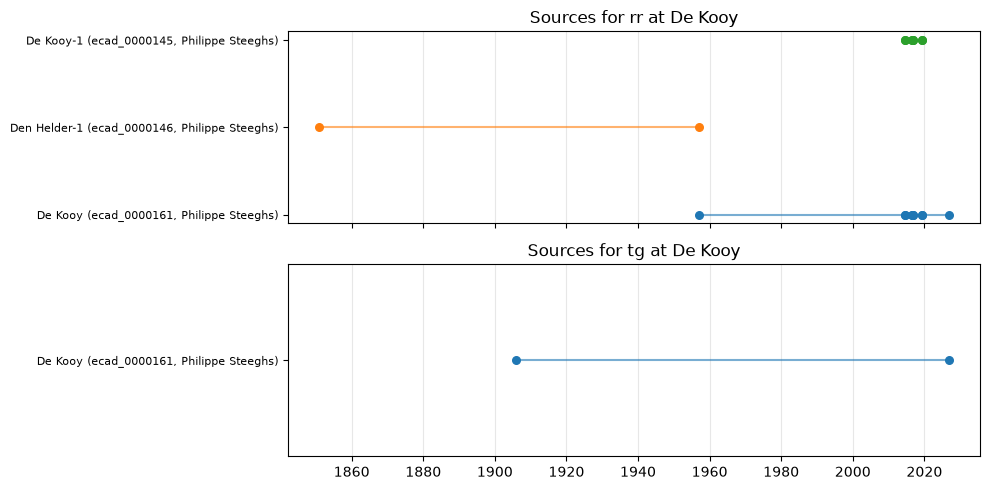

In [5]:
def plot_lineage(lineage, variables):
    fig, axes = plt.subplots(
        len(variables), 1, figsize=(10, 2.5 * len(variables)), sharex=True, squeeze=False
    )
    for ax, variable in zip(axes[:, 0], variables):
        rows = lineage[lineage["variable"] == variable].copy()
        rows["label"] = (
            rows["source_name"]
            + " ("
            + rows["source_id"].fillna("no id")
            + ", "
            + rows["participant"]
            + ")"
        )
        labels = list(dict.fromkeys(rows["label"]))
        for y, label in enumerate(labels):
            for _, row in rows[rows["label"] == label].iterrows():
                ax.plot([row["start"], row["end"]], [y, y], lw=1.5, color=f"C{y % 10}", alpha=0.6)
                ax.scatter([row["start"], row["end"]], [y, y], s=30, color=f"C{y % 10}", zorder=3)
        ax.set_yticks(range(len(labels)))
        ax.set_yticklabels(labels, fontsize=8)
        ax.set_title(f"Sources for {variable} at De Kooy")
        ax.grid(True, axis="x", alpha=0.3)
    fig.tight_layout()


plot_lineage(kooy_lineage, ["rr", "tg"])

## Full blended series of De Kooy

The `/cube` endpoint returns the blended series for each station in the bounding box. It has a limit: the number of time points times the number of parameters times the number of stations must not exceed 300,000.

The next cell requests the full period with a bounding box that is wide enough to include the stations around De Kooy. The request fails with a `413` error. The error message shows the calculation.

In [6]:
try:
    get_json(
        f"{base_url}/collections/{collection}/cube",
        {
            "parameter-name": "rr",
            "method": "sum",
            "bbox": "4.7,52.85,4.85,53.0",
            "datetime": "1851-01-01T00:00:00Z/2026-01-01T00:00:00Z",
        },
    )
except requests.HTTPError as error:
    print(f"HTTP {error.response.status_code}: {error.response.json()['detail']}")

https://api.meteogate.eu/eu-eumetnet-climate-observations/v1/collections/ecad-blended/cube?parameter-name=rr&method=sum&bbox=4.7%2C52.85%2C4.85%2C53.0&datetime=1851-01-01T00%3A00%3A00Z%2F2026-01-01T00%3A00%3A00Z


API call took 0.21 s
HTTP 413: Maximum number of requested data points exceeded (total_datapoints=593,180). Detailed calculation: total_datapoints = timePoints * parameterCount * stationCount = 42,370 * 2 * 7 = 593,180. Maximum allowed: 300,000. Please reduce the number of stations, parameters, or the datetime range.


A bounding box around De Kooy alone returns one station with `rr` and `rr_q`, which stays below the limit. The next cell requests the full period of precipitation at De Kooy.

In [7]:
kooy_cube = get_json(
    f"{base_url}/collections/{collection}/cube",
    {
        "parameter-name": "rr",
        "method": "sum",
        "bbox": "4.775,52.92,4.79,52.93",
        "datetime": "1851-01-01T00:00:00Z/2026-01-01T00:00:00Z",
    },
)
kooy_rr = daily_series(kooy_cube, "ecad_0000161", "rr")
print(f"{kooy_rr.index[0].date()} to {kooy_rr.index[-1].date()}, {len(kooy_rr):,} days")

https://api.meteogate.eu/eu-eumetnet-climate-observations/v1/collections/ecad-blended/cube?parameter-name=rr&method=sum&bbox=4.775%2C52.92%2C4.79%2C52.93&datetime=1851-01-01T00%3A00%3A00Z%2F2026-01-01T00%3A00%3A00Z


API call took 1.1 s
1851-01-01 to 2026-01-01, 63,919 days


The next cell shows which sources contribute to the precipitation series, per decade. A source is listed when its lineage covers at least one day of that decade.

In [8]:
def sources_per_decade(lineage, variable):
    rows = lineage[lineage["variable"] == variable]
    decades = []
    for decade in range(1840, 2030, 10):
        start, end = pd.Timestamp(decade, 1, 1), pd.Timestamp(decade + 10, 1, 1)
        active = rows[(rows["start"] < end) & (rows["end"] >= start)]
        names = ", ".join(sorted(active["source_name"].unique()))
        decades.append(dict(decade=f"{decade}s", sources=names))
    table = pd.DataFrame(decades)
    return table[table["sources"] != ""].set_index("decade")


sources_per_decade(kooy_lineage, "rr")

,sources
decade,
1850s,Den Helder-1
1860s,Den Helder-1
1870s,Den Helder-1
1880s,Den Helder-1
1890s,Den Helder-1
1900s,Den Helder-1
1910s,Den Helder-1
1920s,Den Helder-1
1930s,Den Helder-1


The plot below shows the annual precipitation total of the blended series. The ATBD requires at least 350 valid days for an annual value, so the years with fewer days are removed. The dashed lines mark the start of each source in the lineage.

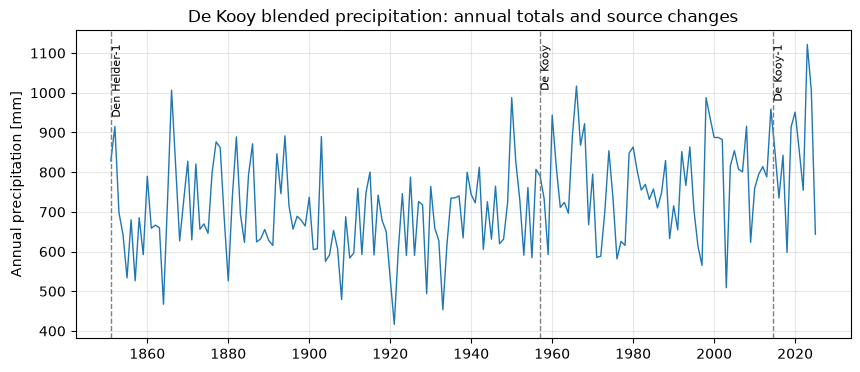

In [9]:
annual = kooy_rr.resample("YS").agg(["sum", "count"])
annual = annual[annual["count"] >= 350]

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(annual.index, annual["sum"], lw=1)
ax.set_ylabel("Annual precipitation [mm]")
ax.set_title("De Kooy blended precipitation: annual totals and source changes")
ax.grid(True, alpha=0.3)

rr_sources = (
    kooy_lineage[kooy_lineage["variable"] == "rr"]
    .groupby("source_name")["start"]
    .min()
    .sort_values()
)
top = annual["sum"].max()
for name, start in rr_sources.items():
    ax.axvline(start, ls="--", color="grey", lw=1)
    ax.text(start, top, f" {name}", rotation=90, va="top", fontsize=8)

## Synoptic extension: Lauwersoog

For recent years, the blended series can be extended with synoptic messages. Lauwersoog (`ecad_0000413`) is an example. Its lineage for mean temperature (`tg`) contains a source named *Lauwersoog Aws* with the participant *Synoptical message from GTS*. This source has no ECA station id.

The next cells find the station, plot its lineage, and then show the blended temperature with the synoptic period shaded.

https://api.meteogate.eu/eu-eumetnet-climate-observations/v1/collections/ecad-blended/locations?bbox=6.1%2C53.3%2C6.3%2C53.5&verbose=true


API call took 0.26 s


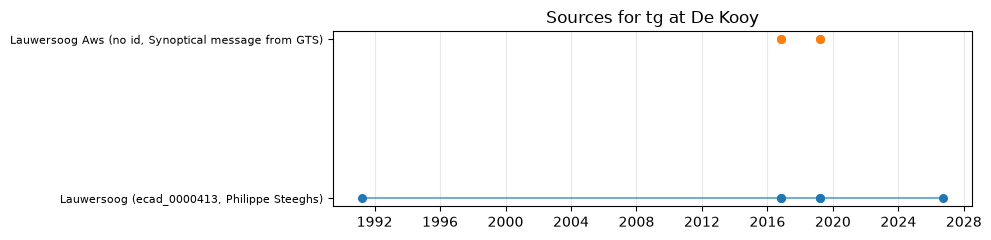

In [10]:
lauw_locations = get_json(
    f"{base_url}/collections/{collection}/locations",
    {"bbox": "6.1,53.3,6.3,53.5", "verbose": "true"},
)
lauwersoog = find_feature(lauw_locations, "ecad_0000413")
lauw_lineage = lineage_table(lauwersoog)
plot_lineage(lauw_lineage, ["tg"])

https://api.meteogate.eu/eu-eumetnet-climate-observations/v1/collections/ecad-blended/cube?parameter-name=tg&method=mean&bbox=6.1%2C53.3%2C6.3%2C53.5&datetime=2010-01-01T00%3A00%3A00Z%2F2020-01-01T00%3A00%3A00Z


API call took 0.46 s


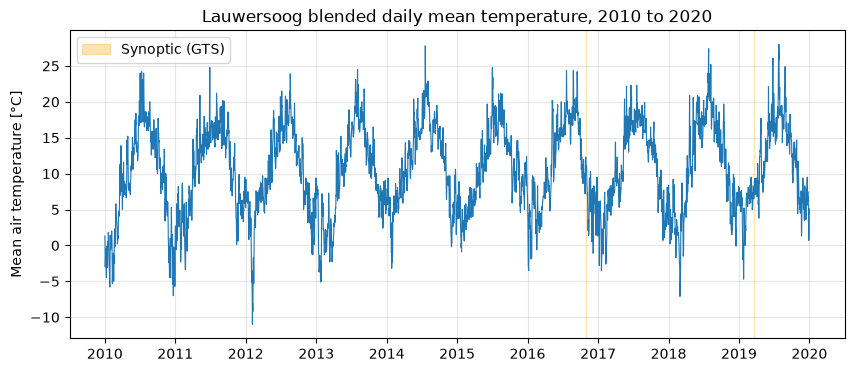

In [11]:
lauw_cube = get_json(
    f"{base_url}/collections/{collection}/cube",
    {
        "parameter-name": "tg",
        "method": "mean",
        "bbox": "6.1,53.3,6.3,53.5",
        "datetime": "2010-01-01T00:00:00Z/2020-01-01T00:00:00Z",
    },
)
lauw_tg = daily_series(lauw_cube, "ecad_0000413", "tg")

gts = lauw_lineage[
    (lauw_lineage["variable"] == "tg")
    & lauw_lineage["participant"].str.startswith("Synoptical")
]

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(lauw_tg.index, lauw_tg, lw=0.8)
for i, (_, row) in enumerate(gts.iterrows()):
    ax.axvspan(
        row["start"], row["end"], color="orange", alpha=0.3,
        label="Synoptic (GTS)" if i == 0 else None,
    )
ax.legend()
ax.set_ylabel("Mean air temperature [°C]")
ax.set_title("Lauwersoog blended daily mean temperature, 2010 to 2020")
ax.grid(True, alpha=0.3)

## Summary

- Use `ecad-blended` for a long, gap-filled series. Use `ecad-nonblended` for the series of one participant.
- The lineage (`verbose=true`) shows which source covers which period. The sources are the nearby stations that fill the series. Synoptic sources have no ECA station id.
- Filter `/locations` with `bbox` or `country_code` when you use `verbose=true`. Without a filter, the response has more than 26,000 stations.
- The `/cube` endpoint allows at most 300,000 data points per request. Use a small bounding box for long periods.
- The timestamps in this collection mark the end of the observation interval (UTC). The archive on ecad.eu uses the start of the interval.